# CALCE CX2 — Three Final Forecasting Models: Tuning, Checkpoints & Inference

**Models reproduced from our earlier FlowState comparative notebook:**
1. `direct_transformer`: 12 observed cycles × 5 charging features, standard positional embedding and Transformer encoder.
2. `time_transformer`: the same model, augmented by the **past observed elapsed-time channel**.
3. `ols_last_CC_CV`: ordinary least squares from the **last observed CC/CV durations** and requested forecast horizon.

**Task:** Forecast SOH at cycle `k + h`, `h ∈ {1,3,5}`, given measured charging features **through cycle `k` only**. This is *forecasting*, not same-cycle SOH estimation. No future SOH or future charging features are available to any model.

**Research protocol:** Training batteries = 5, validation battery = CX2_36, test battery = CX2_38. Use the *already-filtered* training CSV; do not change validation/test. Split windows at gaps, missing cycle ordinals, or reversed timestamps. Fit all transformations only on training data. Search hyperparameters and select checkpoints using **validation only**. Evaluate test only after model selection.

> Important: "best" means **lowest validation RMSE among the configurations tested**, *not* a globally proven optimum. This is a reproducible selection for this fixed battery split. The test battery has been viewed in earlier experiments and should not be regarded as pristine for future research claims. For publication, additionally run a prospective cell-level validation experiment.

**Expected output directory:** `DATA_DIR/three_model_final_results/`. After training it will contain `best_models/`, `tuning_runs.csv`, `validation_leaderboard.csv`, `test_metrics.csv`, `BEST_MODEL_MANIFEST.json`, predictions, and plots.


## Cell 1 — Environment
Install dependencies if needed, then select the intended Python kernel in VS Code. The notebook trains on GPU when available, or CPU otherwise.

In [1]:
# Run once only if packages are missing:
# %pip install torch numpy pandas scikit-learn matplotlib joblib

import os, copy, json, random, time, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import joblib
from IPython.display import display

print('PyTorch:', torch.__version__, 'CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    torch.set_num_threads(min(4, os.cpu_count() or 1))


PyTorch: 2.11.0+cu128 CUDA: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## Cell 2 — Dataset paths and experiment settings

The default is a full validation search over three architecture/optimizer settings and three seeds. Use `RUN_MODE = 'quick'` for a preliminary search, or `'smoke'` to test the code; **only `full` should be used to report tuned results**. The filter CSV must already exist on your Windows machine.

In [2]:
DATA_DIR = Path(r'C:\Projects\Battery_Soh\pre processed ready to use data')
TRAIN_NAME = 'train_final_filtered.csv'
VAL_NAME = 'validation.csv'
TEST_NAME = 'test.csv'
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
TARGET = 'soh'
LOOKBACK = 12
HORIZONS = (1, 3, 5)
MAX_OBSERVED_GAP_H = 24.0

RUN_MODE = 'full'  # 'smoke' (verify), 'quick' (1 seed), 'full' (3 seeds x 3 configs)
SEEDS = [42,123,2026]
BATCH_SIZE = 128
MAX_EPOCHS = 70
PATIENCE = 12
MIN_IMPROVEMENT = 1e-6

# Selection criterion: unweighted mean of validation RMSE across horizons (1,3,5).
# To optimize strictly 1-cycle forecasting instead, set SELECT_HORIZONS=(1,) BEFORE running search.
SELECT_HORIZONS = (1,3,5)

# Architecture grid; original benchmark setting is configuration 0.
TRANSFORMER_GRID = [
    {'hidden':48,'layers':2,'heads':4,'ff_mult':2,'dropout':0.10,'lr':1e-3,'weight_decay':1e-4},
    {'hidden':64,'layers':2,'heads':4,'ff_mult':2,'dropout':0.10,'lr':5e-4,'weight_decay':1e-4},
    {'hidden':48,'layers':1,'heads':4,'ff_mult':2,'dropout':0.05,'lr':5e-4,'weight_decay':1e-4},
]

OUTPUT_DIR = DATA_DIR / 'three_model_final_results'
BEST_DIR = OUTPUT_DIR / 'best_models'
CAND_DIR = OUTPUT_DIR / 'candidate_checkpoints'
for p in (OUTPUT_DIR, BEST_DIR, CAND_DIR): p.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

if RUN_MODE == 'smoke':
    ACTIVE_GRID = TRANSFORMER_GRID[:1]
    ACTIVE_SEEDS = [42]
    ACTIVE_EPOCHS = 2
    ACTIVE_PATIENCE = 2
elif RUN_MODE == 'quick':
    ACTIVE_GRID = TRANSFORMER_GRID
    ACTIVE_SEEDS = [42]
    ACTIVE_EPOCHS = MAX_EPOCHS
    ACTIVE_PATIENCE = PATIENCE
elif RUN_MODE == 'full':
    ACTIVE_GRID = TRANSFORMER_GRID
    ACTIVE_SEEDS = SEEDS
    ACTIVE_EPOCHS = MAX_EPOCHS
    ACTIVE_PATIENCE = PATIENCE
else:
    raise ValueError('RUN_MODE must be smoke, quick, or full')

print('Device:', DEVICE, '| mode:', RUN_MODE, '| saving models to:', BEST_DIR)


Device: cuda | mode: full | saving models to: C:\Projects\Battery_Soh\pre processed ready to use data\three_model_final_results\best_models


## Cell 3 — Load and validate the *exact* CSV files

Refuse a missing filtered CSV rather than silently reverting to unfiltered training. Confirm battery-disjoint splits and schema.

In [3]:
def read_split(filename):
    path=DATA_DIR/filename
    if not path.is_file():
        raise FileNotFoundError(f'{path} does not exist. Verify DATA_DIR and extract/create the filtered train CSV.')
    df=pd.read_csv(path)
    required=['battery','cycle_ordinal','cycle_start',TARGET]+FEATURES
    missing=[c for c in required if c not in df.columns]
    if missing: raise ValueError(f'{filename}: missing columns {missing}')
    df['cycle_start']=pd.to_datetime(df['cycle_start'],errors='raise')
    df=df.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)
    if df[required].isnull().any().any(): raise ValueError(f'{filename}: NaN in required fields')
    if df.duplicated(['battery','cycle_ordinal']).any():
        raise ValueError(f'{filename}: duplicate battery/cycle ordinal')
    if not np.isfinite(df[FEATURES+[TARGET]].to_numpy(dtype=float)).all():
        raise ValueError(f'{filename}: non-finite feature/target')
    return df

train_df=read_split(TRAIN_NAME)
val_df=read_split(VAL_NAME)
test_df=read_split(TEST_NAME)
sets=[set(d['battery']) for d in [train_df,val_df,test_df]]
assert not(sets[0]&sets[1] or sets[0]&sets[2] or sets[1]&sets[2]), 'Battery split leakage!'
for name,df in [('train',train_df),('validation',val_df),('test',test_df)]:
    print(f'{name}: {len(df):,} records; batteries {sorted(df.battery.unique())}')

scaler=StandardScaler().fit(train_df[FEATURES])  # never fit on val/test


train: 7,690 records; batteries ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation: 1,743 records; batteries ['CX2_36']
test: 1,477 records; batteries ['CX2_38']


## Cell 4 — Build leakage-safe historical windows

Each example has inputs from `k-11 … k` and target SOH from `k+h`, for `h=1,3,5`. The last observed SOH is **not** an input. Sequences restart whenever an ordinal is missing, time reverses, or an observed interval exceeds 24h. The first timestep's elapsed time within every window is set to a neutral placeholder because the earlier timestamp is outside the window.

In [4]:
def continuous_segments(frame, min_len=None):
    min_len = min_len or LOOKBACK + max(HORIZONS)
    for battery,g in frame.groupby('battery',sort=True):
        g=g.sort_values('cycle_ordinal').reset_index(drop=True)
        dcycle=g.cycle_ordinal.diff()
        dh=g.cycle_start.diff().dt.total_seconds()/3600
        breaks=(dcycle.ne(1)|dh.le(0)|dh.gt(MAX_OBSERVED_GAP_H)).fillna(True)
        for _,sub in g.groupby(breaks.cumsum()):
            if len(sub)>=min_len:
                yield str(battery),sub.reset_index(drop=True)

train_interval_hours=[]
for _,seg in continuous_segments(train_df, min_len=2):
    train_interval_hours.extend((seg.cycle_start.diff().dt.total_seconds()/3600).dropna().to_list())
if not train_interval_hours: raise ValueError('No contiguous training intervals satisfy the gap cutoff')
DT_SCALE_H=float(np.median(train_interval_hours))
assert DT_SCALE_H>0 and np.isfinite(DT_SCALE_H)
print('Training-only median elapsed hours:',DT_SCALE_H)

class FutureCycleDataset(Dataset):
    def __init__(self, frame, *, smoke=False):
        records=[]
        for battery,seg in continuous_segments(frame):
            x=scaler.transform(seg[FEATURES]).astype('float32')
            y=seg[TARGET].to_numpy(dtype='float32')
            cycles=seg['cycle_ordinal'].to_numpy(dtype='int64')
            hours=seg.cycle_start.diff().dt.total_seconds().to_numpy()/3600
            elapsed=np.ones(len(seg),dtype='float32')
            elapsed[1:]=(hours[1:]/DT_SCALE_H).astype('float32')
            for last in range(LOOKBACK-1, len(seg)-max(HORIZONS)):
                first=last-LOOKBACK+1
                xwindow=x[first:last+1].copy()
                dtwindow=elapsed[first:last+1].copy()
                dtwindow[0]=1.0  # no inference from observation BEFORE the lookback window
                for h in HORIZONS:
                    idx=last+h
                    records.append((xwindow,dtwindow,np.float32(h),np.float32(y[idx]),
                                    battery,int(cycles[idx]),int(cycles[last])))
        if smoke and len(records)>350:
            # Deterministic subsample for smoke test only, no effect on full experiment.
            rng=np.random.default_rng(713)
            ix=sorted(rng.choice(len(records),350,replace=False))
            records=[records[i] for i in ix]
        self.rows=records
    def __len__(self):return len(self.rows)
    def __getitem__(self,index):return self.rows[index]

tr=FutureCycleDataset(train_df,smoke=RUN_MODE=='smoke')
va=FutureCycleDataset(val_df,smoke=RUN_MODE=='smoke')
te=FutureCycleDataset(test_df,smoke=RUN_MODE=='smoke')
print('window/horizon samples:',{'train':len(tr),'validation':len(va),'test':len(te)})
assert all(len(ds)>0 for ds in (tr,va,te)), 'Insufficient uninterrupted windows'
for ds in (tr,va,te):
    assert all(row[5]-row[6]==int(row[2]) for row in ds.rows)
    assert all(row[0].shape==(LOOKBACK,len(FEATURES)) for row in ds.rows)
    assert all(row[1].shape==(LOOKBACK,) for row in ds.rows)

pd.DataFrame({'feature':FEATURES,'mean':scaler.mean_,'std':scaler.scale_}).to_csv(OUTPUT_DIR/'train_feature_scaler.csv',index=False)


Training-only median elapsed hours: 3.885
window/horizon samples: {'train': 8067, 'validation': 1929, 'test': 1491}


## Cell 5 — Model definitions (faithful to our prior benchmark)

The two Transformers differ **only** in the availability of elapsed-time information. Original architecture: linear projection to 48, positional embedding, 2 encoder layers, 4 heads, 96-dimensional feedforward, final-token representation, horizon-conditioned GELU regression head. Hyperparameter search may choose different sizes.

In [5]:
class HorizonHead(nn.Module):
    def __init__(self,hidden):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,1))
    def forward(self,z,h):
        scaled_h=h.reshape(-1,1)/float(max(HORIZONS))
        return self.net(torch.cat([z,scaled_h],dim=1)).squeeze(-1)

class SOHTransformer(nn.Module):
    def __init__(self, *, time_aware, hidden=48, layers=2, heads=4, ff_mult=2, dropout=0.1):
        super().__init__()
        assert hidden%heads==0
        self.time_aware=bool(time_aware)
        self.emb=nn.Linear(len(FEATURES)+int(self.time_aware),hidden)
        self.pos=nn.Parameter(torch.zeros(1,LOOKBACK,hidden))
        encoder_layer=nn.TransformerEncoderLayer(
            d_model=hidden,nhead=heads,dim_feedforward=hidden*ff_mult,
            dropout=dropout,batch_first=True,norm_first=True,activation='relu'
        )
        self.encoder=nn.TransformerEncoder(encoder_layer,num_layers=layers,enable_nested_tensor=False)
        self.head=HorizonHead(hidden)

    def forward(self,x,dt,h):
        if self.time_aware:
            x=torch.cat([x,torch.log1p(dt.clamp_min(0)).unsqueeze(-1)],dim=-1)
        encoded=self.encoder(self.emb(x)+self.pos)
        return self.head(encoded[:,-1,:],h)

MODEL_FAMILIES=('direct_transformer','time_transformer','ols_last_CC_CV')

def make_neural(family,cfg):
    assert family in MODEL_FAMILIES[:2]
    return SOHTransformer(time_aware=family=='time_transformer',**{
        k:cfg[k] for k in ['hidden','layers','heads','ff_mult','dropout']
    })

def count_parameters(m):return sum(p.numel() for p in m.parameters() if p.requires_grad)

for family in MODEL_FAMILIES[:2]:
    model=make_neural(family,TRANSFORMER_GRID[0])
    print(family, 'original config params:',count_parameters(model))


direct_transformer original config params: 41233
time_transformer original config params: 41281


## Cell 6 — Forward-pass and causality tests

In [6]:
batch=next(iter(DataLoader(tr,batch_size=min(8,len(tr)),shuffle=False)))
x,dt,h,y,battery,target_cycle,last_cycle=batch
assert torch.all(target_cycle-last_cycle==h.long())
assert torch.isfinite(x).all() and torch.isfinite(dt).all()
for fam in MODEL_FAMILIES[:2]:
    model=make_neural(fam,TRANSFORMER_GRID[0]).to(DEVICE)
    result=model(x.to(DEVICE),dt.to(DEVICE),h.to(DEVICE))
    assert result.shape==y.shape and torch.isfinite(result).all()
    result.square().mean().backward()
    assert any(param.grad is not None for param in model.parameters())

# Simulate leakage test: any forecast-label change cannot alter input tensors.
orig_x=tr[0][0].copy(); orig_dt=tr[0][1].copy()
assert np.array_equal(orig_x,tr[0][0]) and np.array_equal(orig_dt,tr[0][1])
print('Shape, horizon, forward/backprop checks passed.')


Shape, horizon, forward/backprop checks passed.


## Cell 7 — Training, validation and metric utilities

In [7]:
def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def loader(ds,shuffle=False):
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)

def measure(frame):
    y=frame.actual_soh.to_numpy(dtype=float)
    yhat=frame.predicted_soh.to_numpy(dtype=float)
    return dict(RMSE=float(np.sqrt(np.mean((yhat-y)**2))),
                MAE=float(np.mean(np.abs(yhat-y))),
                MAPE=float(np.mean(np.abs(yhat-y)/np.maximum(np.abs(y),1e-6))*100),
                R2=float(r2_score(y,yhat)) if len(y)>1 and np.var(y)>0 else float('nan'),
                n=int(len(y)))

def to_prediction_frame(meta, y, predicted):
    f=pd.DataFrame(meta,columns=['battery','target_cycle','last_input_cycle','horizon'])
    f['actual_soh']=y
    f['predicted_soh']=predicted
    f['error']=f.predicted_soh-f.actual_soh
    return f

@torch.no_grad()
def predict_neural(model, ds):
    model.eval(); yp=[]; y=[]; metadata=[]
    for x,dt,h,target,battery,target_cycle,last_cycle in loader(ds):
        estimates=model(x.to(DEVICE),dt.to(DEVICE),h.to(DEVICE)).cpu().numpy()
        yp.extend(estimates.tolist()); y.extend(target.numpy().tolist())
        metadata.extend(zip(list(battery),target_cycle.numpy().tolist(),last_cycle.numpy().tolist(),h.numpy().tolist()))
    return to_prediction_frame(metadata,y,yp)

def split_scores(pred):
    return {int(h):measure(piece) for h,piece in pred.groupby('horizon')}

def validation_score(pred):
    ms=split_scores(pred)
    return float(np.mean([ms[h]['RMSE'] for h in SELECT_HORIZONS]))

def ols_array(ds):
    X=[];Y=[];meta=[]
    for x,dt,h,y,battery,target,last in ds.rows:
        X.append([float(x[-1,0]),float(x[-1,1]),float(h/max(HORIZONS))])
        Y.append(float(y)); meta.append((battery,target,last,float(h)))
    return np.asarray(X,dtype=float),np.asarray(Y,dtype=float),meta

def predict_ols(ols,ds):
    X,y,meta=ols_array(ds)
    return to_prediction_frame(meta,y,ols.predict(X))


## Cell 8 — Validation-based hyperparameter search

Each model/config/seed is trained independently. The lowest validation score epoch is restored. We choose a **configuration by its mean validation RMSE across seeds**, then choose the representative checkpoint by lowest validation score within that configuration. The outer test split is *not read in this cell*.

In [8]:
tuning_rows=[]
checkpoint_index={}

for family in MODEL_FAMILIES[:2]:
    for cfg_idx,cfg in enumerate(ACTIVE_GRID):
        for seed in ACTIVE_SEEDS:
            seed_everything(seed)
            model=make_neural(family,cfg).to(DEVICE)
            optimizer=torch.optim.AdamW(model.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay'])
            best=float('inf');best_epoch=-1;best_weights=None;bad_epochs=0;history=[]
            start=time.perf_counter()
            for epoch in range(1,ACTIVE_EPOCHS+1):
                model.train(); loss_sum=0.0
                for x,dt,h,y,*_ in loader(tr,shuffle=True):
                    x=x.to(DEVICE);dt=dt.to(DEVICE);h=h.to(DEVICE);y=y.to(DEVICE)
                    optimizer.zero_grad(set_to_none=True)
                    pred=model(x,dt,h)
                    loss=F.mse_loss(pred,y)
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(),1.0)
                    optimizer.step()
                    loss_sum+=float(loss.item())*len(y)
                val_pred=predict_neural(model,va)
                val_metric=validation_score(val_pred)
                history.append({'epoch':epoch,'train_RMSE':np.sqrt(loss_sum/len(tr)),
                                'validation_score':val_metric})
                if val_metric < best - MIN_IMPROVEMENT:
                    best=val_metric;best_epoch=epoch
                    best_weights=copy.deepcopy(model.state_dict());bad_epochs=0
                else:
                    bad_epochs+=1
                if bad_epochs>=ACTIVE_PATIENCE:break

            model.load_state_dict(best_weights)
            restored_pred=predict_neural(model,va)
            restored_score=validation_score(restored_pred)
            seconds=time.perf_counter()-start
            prefix=f'{family}_cfg{cfg_idx}_seed{seed}'
            ckpt_path=CAND_DIR/f'{prefix}.pt'
            torch.save({'model_state':model.state_dict(),'family':family,
                        'hyperparameters':cfg,'seed':seed,'best_epoch':best_epoch,
                        'lookback':LOOKBACK,'horizons':HORIZONS,'features':FEATURES,
                        'scaler_mean':scaler.mean_.tolist(), 'scaler_scale':scaler.scale_.tolist(),
                        'dt_scale_h':DT_SCALE_H,'max_observed_gap_h':MAX_OBSERVED_GAP_H}, ckpt_path)
            checkpoint_index[(family,cfg_idx,seed)]=ckpt_path
            pd.DataFrame(history).to_csv(OUTPUT_DIR/f'{prefix}_history.csv',index=False)
            restored_pred.to_csv(OUTPUT_DIR/f'{prefix}_validation_predictions.csv',index=False)
            tuning_rows.append({'family':family,'config_id':cfg_idx,'seed':seed,'best_epoch':best_epoch,
                                'validation_RMSE_score':restored_score,'parameters':count_parameters(model),
                                'train_seconds':seconds,'checkpoint':str(ckpt_path),**cfg})
            print(f'{family} config={cfg_idx} seed={seed} best_val={restored_score:.6f} '
                  f'best_epoch={best_epoch} seconds={seconds:.1f}')

tuning=pd.DataFrame(tuning_rows)
tuning.to_csv(OUTPUT_DIR/'tuning_runs.csv',index=False)
config_summary=tuning.groupby(['family','config_id'],as_index=False).agg(
    validation_RMSE_mean=('validation_RMSE_score','mean'),
    validation_RMSE_std=('validation_RMSE_score','std'),
    seeds=('seed','nunique'),parameters=('parameters','first'))
config_summary.to_csv(OUTPUT_DIR/'validation_config_summary.csv',index=False)
display(config_summary.sort_values(['family','validation_RMSE_mean']))


direct_transformer config=0 seed=42 best_val=0.013403 best_epoch=36 seconds=71.4
direct_transformer config=0 seed=123 best_val=0.014407 best_epoch=26 seconds=56.1
direct_transformer config=0 seed=2026 best_val=0.013449 best_epoch=40 seconds=147.1
direct_transformer config=1 seed=42 best_val=0.011785 best_epoch=38 seconds=142.1
direct_transformer config=1 seed=123 best_val=0.013602 best_epoch=46 seconds=171.1
direct_transformer config=1 seed=2026 best_val=0.014174 best_epoch=22 seconds=138.8
direct_transformer config=2 seed=42 best_val=0.013798 best_epoch=18 seconds=80.5
direct_transformer config=2 seed=123 best_val=0.019621 best_epoch=31 seconds=114.9
direct_transformer config=2 seed=2026 best_val=0.013829 best_epoch=58 seconds=206.2
time_transformer config=0 seed=42 best_val=0.016292 best_epoch=18 seconds=110.7
time_transformer config=0 seed=123 best_val=0.012129 best_epoch=21 seconds=6275.6
time_transformer config=0 seed=2026 best_val=0.020770 best_epoch=2 seconds=56.6
time_transform

,family,config_id,validation_RMSE_mean,validation_RMSE_std,seeds,parameters
1,direct_transformer,1,0.013187,0.001248,3,72385
0,direct_transformer,0,0.013753,0.000567,3,41233
2,direct_transformer,2,0.015750,0.003353,3,22273
4,time_transformer,1,0.011991,0.000815,3,72449
5,time_transformer,2,0.012615,0.000490,3,22321
3,time_transformer,0,0.016397,0.004322,3,41281


## Cell 9 — Select best neural configurations, fit OLS, save final artifacts

For transparency, the model-selection criterion is fixed before inspecting the test. `best_models/` stores one selected checkpoint per Transformer family and a fitted OLS model, along with a manifest containing all settings and the training-only preprocessing.

In [9]:
best_model_records=[]
selected_models={}
selected_predictions={}
for family in MODEL_FAMILIES[:2]:
    family_summary=config_summary.query('family==@family').sort_values('validation_RMSE_mean')
    cfg_id=int(family_summary.iloc[0]['config_id'])
    candidates=tuning[(tuning.family==family)&(tuning.config_id==cfg_id)]
    representative=candidates.sort_values('validation_RMSE_score').iloc[0]
    cfg=ACTIVE_GRID[cfg_id];seed=int(representative.seed)
    model=make_neural(family,cfg).to(DEVICE)
    source=torch.load(checkpoint_index[(family,cfg_id,seed)],map_location=DEVICE,weights_only=False)
    model.load_state_dict(source['model_state']);model.eval()
    best_path=BEST_DIR/f'{family}_best.pt'
    torch.save({**source,'selection':'lowest mean validation score across seeds; representative seed lowest within config',
                'mean_validation_RMSE':float(family_summary.iloc[0].validation_RMSE_mean),
                'run_mode':RUN_MODE},best_path)
    selected_models[family]=model
    val_pred=predict_neural(model,va)
    val_pred.to_csv(OUTPUT_DIR/f'{family}_selected_validation_predictions.csv',index=False)
    selected_predictions[family]=val_pred
    best_model_records.append({'model':family,'type':'PyTorch','checkpoint':str(best_path),
              'config_id':cfg_id,'seed':seed,'validation_RMSE_mean_across_seeds':float(family_summary.iloc[0].validation_RMSE_mean),
              'representative_validation_RMSE':validation_score(val_pred),
              'hyperparameters':cfg,'parameters':count_parameters(model)})

Xtr,Ytr,_=ols_array(tr)
Xva,Yva,_=ols_array(va)
ols=LinearRegression().fit(Xtr,Ytr)
ols_path=BEST_DIR/'ols_last_CC_CV_best.joblib'
joblib.dump(ols,ols_path)
selected_models['ols_last_CC_CV']=ols
val_ols=predict_ols(ols,va)
val_ols.to_csv(OUTPUT_DIR/'ols_last_CC_CV_selected_validation_predictions.csv',index=False)
selected_predictions['ols_last_CC_CV']=val_ols
best_model_records.append({'model':'ols_last_CC_CV','type':'sklearn.LinearRegression','checkpoint':str(ols_path),
       'validation_RMSE_mean_across_seeds':validation_score(val_ols),
       'representative_validation_RMSE':validation_score(val_ols),'hyperparameters':{'fit_intercept':True},
       'coefficients':ols.coef_.tolist(),'intercept':float(ols.intercept_),'parameters':4})

best_records=pd.DataFrame([{k:v for k,v in record.items() if k not in ('hyperparameters','coefficients')} for record in best_model_records])
best_records.sort_values('validation_RMSE_mean_across_seeds').to_csv(OUTPUT_DIR/'validation_leaderboard.csv',index=False)

WINNER=min(best_model_records,key=lambda r:r['validation_RMSE_mean_across_seeds'])
manifest={'winner_model':WINNER['model'],'winner_checkpoint':WINNER['checkpoint'],
          'selection_metric':'mean validation RMSE across selected forecast horizons',
          'selection_horizons':list(SELECT_HORIZONS),'task':'future_cycle_soh_forecasting',
          'note':'Only best of searched configs. Test is for reporting, not selection.',
          'run_mode':RUN_MODE,'features':FEATURES,'target':TARGET,
          'lookback':LOOKBACK,'horizons':list(HORIZONS),'max_gap_hours':MAX_OBSERVED_GAP_H,
          'train_filename':TRAIN_NAME,'validation_filename':VAL_NAME,'test_filename':TEST_NAME,
          'scaler_mean':scaler.mean_.tolist(),'scaler_scale':scaler.scale_.tolist(),
          'dt_scale_hours':DT_SCALE_H,'all_models':best_model_records}
with open(OUTPUT_DIR/'BEST_MODEL_MANIFEST.json','w') as fp:json.dump(manifest,fp,indent=2)

print('BEST MODEL BY VALIDATION:',WINNER['model'])
display(best_records.sort_values('validation_RMSE_mean_across_seeds'))
print('Models saved in:',BEST_DIR)


BEST MODEL BY VALIDATION: ols_last_CC_CV


,model,type,checkpoint,config_id,seed,validation_RMSE_mean_across_seeds,representative_validation_RMSE,parameters,intercept
2,ols_last_CC_CV,sklearn.LinearRegression,C:\Projects\Battery_Soh\pre processed ready to...,NaN,NaN,0.010272,0.010272,4,0.788817
1,time_transformer,PyTorch,C:\Projects\Battery_Soh\pre processed ready to...,1.0,2026.0,0.011991,0.011516,72449,NaN
0,direct_transformer,PyTorch,C:\Projects\Battery_Soh\pre processed ready to...,1.0,42.0,0.013187,0.011785,72385,NaN


Models saved in: C:\Projects\Battery_Soh\pre processed ready to use data\three_model_final_results\best_models


## Cell 10 — Report on the held-out test (only after selection)

Reports all three selected models at horizons 1/3/5. **Do not retune based on these numbers**. The winner recorded above remains the validation-selected winner.

In [10]:
all_test_rows=[]
all_val_rows=[]
for family in MODEL_FAMILIES:
    model=selected_models[family]
    test_pred=(predict_ols(model,te) if family=='ols_last_CC_CV' else predict_neural(model,te))
    test_pred.to_csv(OUTPUT_DIR/f'{family}_selected_test_predictions.csv',index=False)
    for split,pred in [('validation',selected_predictions[family]),('test',test_pred)]:
        for horizon,part in pred.groupby('horizon'):
            row={'split':split,'model':family,'horizon':int(horizon),**measure(part)}
            (all_val_rows if split=='validation' else all_test_rows).append(row)
validation_metrics=pd.DataFrame(all_val_rows)
test_metrics=pd.DataFrame(all_test_rows)
validation_metrics.to_csv(OUTPUT_DIR/'validation_metrics.csv',index=False)
test_metrics.to_csv(OUTPUT_DIR/'test_metrics.csv',index=False)
print('Validation metrics:')
display(validation_metrics.sort_values(['horizon','RMSE']))
print('Test metrics (REPORT ONLY):')
display(test_metrics.sort_values(['horizon','RMSE']))


Validation metrics:


,split,model,horizon,RMSE,MAE,MAPE,R2,n
6,validation,ols_last_CC_CV,1,0.008425,0.006087,0.816414,0.995022,643
0,validation,direct_transformer,1,0.010286,0.007731,1.101056,0.992579,643
3,validation,time_transformer,1,0.010349,0.007255,1.048745,0.992488,643
7,validation,ols_last_CC_CV,3,0.010678,0.007842,1.061537,0.992002,643
4,validation,time_transformer,3,0.011761,0.008467,1.201999,0.990299,643
1,validation,direct_transformer,3,0.012081,0.009116,1.286833,0.989763,643
8,validation,ols_last_CC_CV,5,0.011711,0.008247,1.130289,0.990353,643
5,validation,time_transformer,5,0.012438,0.008721,1.239074,0.989119,643
2,validation,direct_transformer,5,0.012986,0.009594,1.356339,0.988138,643


Test metrics (REPORT ONLY):


,split,model,horizon,RMSE,MAE,MAPE,R2,n
0,test,direct_transformer,1,0.011602,0.009912,1.211661,0.990330,497
3,test,time_transformer,1,0.012992,0.011106,1.439686,0.987874,497
6,test,ols_last_CC_CV,1,0.014227,0.013066,1.662961,0.985459,497
1,test,direct_transformer,3,0.012377,0.010341,1.269759,0.989019,497
4,test,time_transformer,3,0.013484,0.011293,1.462018,0.986968,497
7,test,ols_last_CC_CV,3,0.015290,0.013674,1.746386,0.983242,497
2,test,direct_transformer,5,0.012967,0.010792,1.323021,0.988026,497
5,test,time_transformer,5,0.014268,0.012109,1.570840,0.985503,497
8,test,ols_last_CC_CV,5,0.015728,0.014123,1.815891,0.982384,497


## Cell 11 — Plots, model descriptions and output manifest

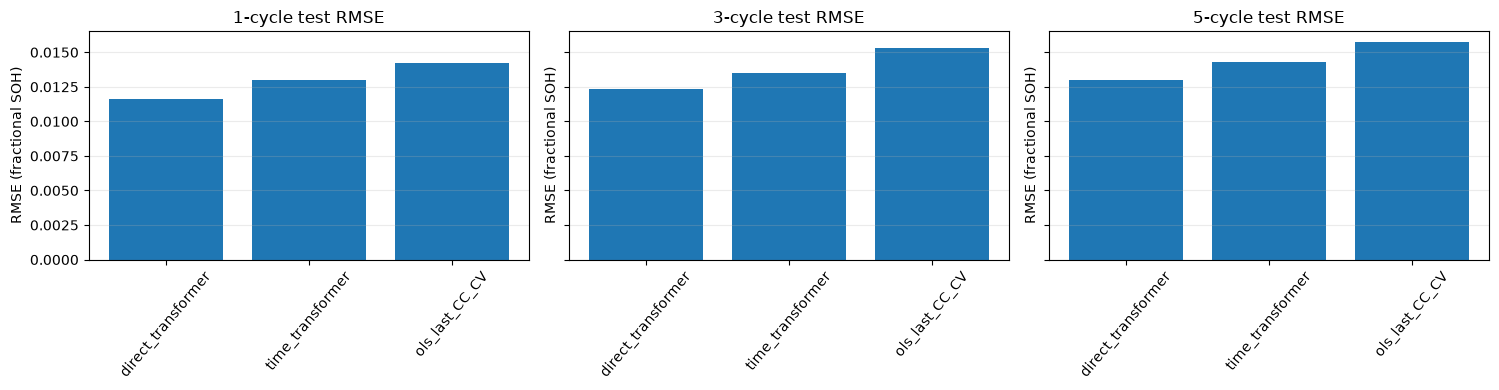

Saved outputs:
 - BEST_MODEL_MANIFEST.json
 - best_models
 - candidate_checkpoints
 - direct_transformer_cfg0_seed123_history.csv
 - direct_transformer_cfg0_seed123_validation_predictions.csv
 - direct_transformer_cfg0_seed2026_history.csv
 - direct_transformer_cfg0_seed2026_validation_predictions.csv
 - direct_transformer_cfg0_seed42_history.csv
 - direct_transformer_cfg0_seed42_validation_predictions.csv
 - direct_transformer_cfg1_seed123_history.csv
 - direct_transformer_cfg1_seed123_validation_predictions.csv
 - direct_transformer_cfg1_seed2026_history.csv
 - direct_transformer_cfg1_seed2026_validation_predictions.csv
 - direct_transformer_cfg1_seed42_history.csv
 - direct_transformer_cfg1_seed42_validation_predictions.csv
 - direct_transformer_cfg2_seed123_history.csv
 - direct_transformer_cfg2_seed123_validation_predictions.csv
 - direct_transformer_cfg2_seed2026_history.csv
 - direct_transformer_cfg2_seed2026_validation_predictions.csv
 - direct_transformer_cfg2_seed42_history.c

In [11]:
fig,axes=plt.subplots(1,len(HORIZONS),figsize=(15,4),sharey=True)
for ax,h in zip(axes,HORIZONS):
    t=test_metrics[test_metrics.horizon==h].sort_values('RMSE')
    ax.bar(t.model,t.RMSE)
    ax.tick_params(axis='x',rotation=50)
    ax.set_title(f'{h}-cycle test RMSE')
    ax.set_ylabel('RMSE (fractional SOH)')
    ax.grid(axis='y',alpha=.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'test_RMSE_by_horizon.png',dpi=170)
plt.show()

print('Saved outputs:')
for f in sorted(OUTPUT_DIR.iterdir()):
    print(' -',f.name)


## Cell 12 — Reload the saved models and forecast from 12 new observed cycles

Use this after training or in another notebook with the same model class definitions. New observations must contain *all five input features* and valid `cycle_start` timestamps. No future features/labels are needed. **Do not provide records separated by missing ordinals or >24 hours**, since this trained version does not extrapolate across them.

In [12]:
def reload_saved_family(family):
    if family=='ols_last_CC_CV':
        return joblib.load(BEST_DIR/'ols_last_CC_CV_best.joblib')
    payload=torch.load(BEST_DIR/f'{family}_best.pt',map_location=DEVICE,weights_only=False)
    m=make_neural(family,payload['hyperparameters']).to(DEVICE)
    m.load_state_dict(payload['model_state']);m.eval()
    return m

@torch.no_grad()
def forecast_from_history(recent_df, family, horizon, model=None):
    """recent_df: >=12 chronologically ordered records from ONE battery; no SOH required."""
    if horizon not in HORIZONS:raise ValueError(f'horizon must be one of {HORIZONS}')
    missing=set(['cycle_ordinal','cycle_start']+FEATURES)-set(recent_df.columns)
    if missing:raise ValueError(f'Missing columns {missing}')
    recent=recent_df.sort_values('cycle_ordinal').tail(LOOKBACK).copy()
    if len(recent)!=LOOKBACK:raise ValueError(f'Need {LOOKBACK} historical cycles')
    recent['cycle_start']=pd.to_datetime(recent['cycle_start'])
    dc=recent['cycle_ordinal'].diff().iloc[1:]
    dh=recent['cycle_start'].diff().dt.total_seconds().iloc[1:]/3600
    if not (dc==1).all() or not ((dh>0)&(dh<=MAX_OBSERVED_GAP_H)).all():
        raise ValueError('Recent observations are not contiguous or have unknown large gaps')
    x=scaler.transform(recent[FEATURES]).astype('float32')
    elapsed=np.ones(LOOKBACK,dtype='float32')
    elapsed[1:]=(dh.to_numpy()/DT_SCALE_H).astype('float32')
    model=model or reload_saved_family(family)
    if family=='ols_last_CC_CV':
        return float(model.predict([[float(x[-1,0]),float(x[-1,1]),horizon/max(HORIZONS)]])[0])
    xb=torch.from_numpy(x[None]).to(DEVICE)
    tb=torch.from_numpy(elapsed[None]).to(DEVICE)
    hb=torch.tensor([float(horizon)],device=DEVICE)
    return float(model(xb,tb,hb).item())

example=test_df[test_df.battery==test_df.battery.iloc[0]].sort_values('cycle_ordinal').head(LOOKBACK)
try:
    print('Example forecast for 1 cycle (demonstration, not test selection):',
          forecast_from_history(example,WINNER['model'],horizon=1))
except ValueError as exc:
    print('Example could not be used because the earliest 12 cycles are discontinuous:',exc)


Example forecast for 1 cycle (demonstration, not test selection): 1.0044608755587854


## Reading the outputs and next experiments

1. `validation_config_summary.csv` — the hyperparameter winner in each Transformer family, **mean across seeds** (full mode).
2. `validation_leaderboard.csv` — validation-based selection across the three families.
3. `best_models/direct_transformer_best.pt`, `best_models/time_transformer_best.pt`, `best_models/ols_last_CC_CV_best.joblib` — loadable trained models.
4. `BEST_MODEL_MANIFEST.json` — selected winner and its exact configuration, input scaler, and time normalization.
5. `test_metrics.csv` — final reporting by horizon; *not for additional tuning*.

**Key scientific controls:** These models solve next-cycle/multi-horizon forecasting (not current-cycle estimation). One battery is insufficient to claim cross-cell superiority; repeat with other unseen battery splits. We have already inspected CX2_38 many times, so an independent test set is needed before publication-level claims. Observed time gaps do not prove rest. The SOH filter is a sensitivity dataset, not a verified correction of every removed measurement.
